# Week 4. Convergence of diffusion models

This notebook accompanies Chapter 5 of the notes. Chapter 5 bounds the error of a diffusion model in
terms of three sources: the initialisation from $\mathcal N(0,I_n)$ instead of $q_T$, the learned score, and the time
discretisation. Its convergence theorem assumes uniformly Lipschitz scores. The Gaussian examples below show how a large Lipschitz constant affects sampling.

1. For Gaussian data and the exact score, the sampler's output is Gaussian and its error can be computed
   exactly. We use this to compare samplers and time grids, for spread-out data and for data close to a
   point mass.
2. We then train a diffusion model on MNIST and sample from it.

Section 1 runs in seconds. Section 2 trains a small neural network. It takes about seven minutes on a recent
laptop GPU (Apple silicon or CUDA) and much longer on a CPU, where you may want to reduce `NUM_STEPS`.

In [1]:
import math
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import torch
from torchvision import datasets, transforms

from mnist_unet import UNet

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
torch.manual_seed(4)
device = torch.device("cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu")
print("device:", device)

device: mps


## 1. Exact errors for Gaussian data

Let $q=\mathcal N(0,vI_n)$. Then $q_\tau=\mathcal N(0,\lambda_\tau I_n)$ with $\lambda_\tau=e^{-2\tau}v+1-e^{-2\tau}$, and the exact score is $s_\tau(x)=-x/\lambda_\tau$. On a grid
$0=t_0<\dots<t_K=T-\delta$ with steps $h_k$ and forward levels $\tau_k=T-t_k$, each of the following samplers is a linear
recursion $Y_{k+1}=a_kY_k+b_k\xi_k$, so the output is $\mathcal N(0,P_KI_n)$ with $P_{k+1}=a_k^2P_k+b_k^2$ and $P_0=1$.

- **Euler–Maruyama** for the reverse SDE, $Y_{k+1}=Y_k+h_k[Y_k+2s_{\tau_k}(Y_k)]+\sqrt{2h_k}\,\xi_k$.
- **Exponential integrator** (Chapter 5), which freezes the score on each step and solves the remaining linear SDE
  exactly, $Y_{k+1}=e^{h_k}Y_k+2(e^{h_k}-1)s_{\tau_k}(Y_k)+\sqrt{e^{2h_k}-1}\,\xi_k$.
The error is $\mathrm{KL}(q_\delta\,\|\,\mathcal N(0,P_KI_n))=\frac n2\bigl(\lambda_\delta/P_K-1-\log(\lambda_\delta/P_K)\bigr)$. We compare two grids with the same number of steps
$K$. The *uniform* grid has equal steps. For an empirical comparison, a *two-phase* grid has $K/2$ equal steps on $[0,T-1]$ and $K/2$
steps on $[T-1,T-\delta]$ along which the noise level $T-t_k$ decreases geometrically from $1$ to $\delta$.
The two-phase grid is a practical choice here. Both Gaussian targets have uniformly Lipschitz scores.


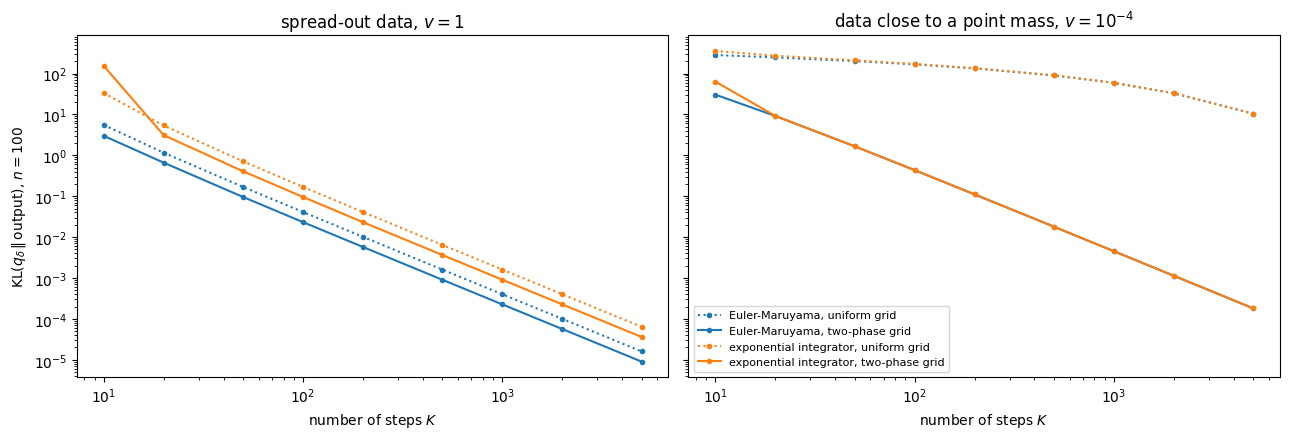

In [ ]:
def grid(T, delta, K, kind):
    if kind == "uniform":
        return np.linspace(0, T - delta, K + 1)
    if T <= 1:
        raise ValueError(f"the two-phase grid needs T > 1, got T = {T}")
    first = np.linspace(0, T - 1, K // 2 + 1)
    second = T - np.geomspace(1.0, delta, K - K // 2 + 1)
    return np.concatenate([first, second[1:]])

def output_variance(v, ts, T, sampler):
    lam = lambda tau: np.exp(-2 * tau) * v + 1 - np.exp(-2 * tau)
    P = 1.0
    for t0, t1 in zip(ts[:-1], ts[1:]):
        h, tau0 = t1 - t0, T - t0
        c = -1.0 / lam(tau0)                              # score at level tau0 is c * y
        if sampler == "Euler-Maruyama":
            a, b2 = 1 + h + 2 * h * c, 2 * h
        elif sampler == "exponential integrator":
            a, b2 = np.exp(h) + 2 * (np.exp(h) - 1) * c, np.exp(2 * h) - 1
        else:
            raise ValueError(f"Unknown sampler: {sampler}")
        P = a * a * P + b2
    return P

def kl_error(v, K, kind, sampler, n=100, T=8.0, delta=1e-3):
    lam_delta = np.exp(-2 * delta) * v + 1 - np.exp(-2 * delta)
    P = output_variance(v, grid(T, delta, K, kind), T, sampler)
    r = lam_delta / P
    return 0.5 * n * (r - 1 - np.log(r)) if np.isfinite(P) and P > 0 else np.inf

Ks = np.array([10, 20, 50, 100, 200, 500, 1000, 2000, 5000])
samplers = ["Euler-Maruyama", "exponential integrator"]
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for a_, v, title in [(ax[0], 1.0, "spread-out data, $v=1$"), (ax[1], 1e-4, "data close to a point mass, $v=10^{-4}$")]:
    for sampler, color in zip(samplers, ["tab:blue", "tab:orange"]):
        for kind, ls in [("uniform", ":"), ("two-phase", "-")]:
            errs = np.array([kl_error(v, K, kind, sampler) for K in Ks])
            a_.loglog(Ks, errs, ls, color=color, marker="o", ms=3, label=f"{sampler}, {kind} grid")
    a_.set_xlabel("number of steps $K$"); a_.set_title(title)
ax[0].set_ylabel(r"$\mathrm{KL}(q_\delta\,\|\,\mathrm{output})$, $n=100$"); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

For $v>0$, the scores are uniformly Lipschitz, with $L=\max\{1,1/v\}$.
The nearly singular example therefore has $L=10^4$.
Compare how the two samplers resolve this rapidly varying score on each grid.
The two-phase grid concentrates steps near the end, where the noise is small.

These plots measure error in the final law.
Chapter 5 bounds error through whole path laws, which can give a larger bound.
For standard Gaussian data, the final relative entropy can decay like $K^{-2}$,
faster than the path-space bound of order $K^{-1}$.

*Things to try.* Change $n$. In this product example the error is proportional to the dimension.
Replace $v=10^{-4}$ by $v=10$, so that the data are more spread out than
the noise, and pass `T=2.0` to `kl_error`. The error then stops decreasing at about $10^{-2}$, while with $T=8$ it keeps
decreasing. This floor is the initialisation error, the part of the error caused by starting from $\mathcal N(0,I_n)$
instead of $q_T$. With the two variances used above it is invisible. For $v=1$ we have $q_T=\gamma_n$ exactly, and for
$v=10^{-4}$ the reverse dynamics shrinks the initial error to about $10^{-11}$.

## 2. A diffusion model for MNIST

We now train a diffusion model on the $60\,000$ handwritten digits of MNIST, images of $28\times28$ pixels rescaled to
$[-1,1]$, so the dimension is $n=784$. The network (in `mnist_unet.py`) is a small U-Net with about one million
parameters. As in Chapter 4, it predicts the noise $Z$ in $\bar X_\tau=e^{-\tau}\bar X_0+\sigma_\tau Z$, and the score is recovered as
$\hat s_\tau=-\hat Z/\sigma_\tau$. Minimising $\mathbb E|\hat Z-Z|^2$ is denoising score matching with the weight $\sigma_\tau^2$. The noise levels are drawn
log-uniformly between $10^{-3}$ and $T=5$, so that small noise levels, where the score varies fastest, are well
represented.

data: (60000, 1, 28, 28)


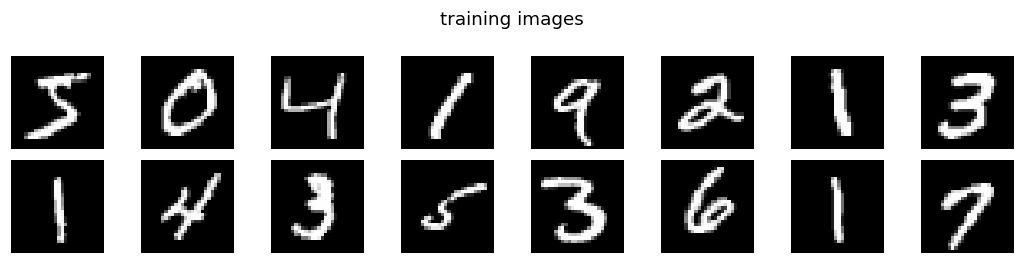

In [3]:
import contextlib, io
transform = transforms.Compose([transforms.ToTensor(), transforms.Lambda(lambda x: 2 * x - 1)])
with contextlib.redirect_stderr(io.StringIO()):                 # silence the download progress bars
    mnist = datasets.MNIST(root="data", train=True, download=True, transform=transform)
    mnist_test = datasets.MNIST(root="data", train=False, download=True, transform=transform)
images = torch.stack([mnist[i][0] for i in range(len(mnist))]).to(device)     # (60000, 1, 28, 28)
print("data:", tuple(images.shape))

def show(imgs, nrow=8, title=None, scale=1.2):
    imgs = imgs.detach().clamp(-1, 1).cpu()
    ncol = math.ceil(len(imgs) / nrow)
    fig, ax = plt.subplots(ncol, nrow, figsize=(nrow * scale, ncol * scale))
    for a_, im in zip(np.array(ax).ravel(), imgs):
        a_.imshow(im[0], cmap="gray", vmin=-1, vmax=1)
    for a_ in np.array(ax).ravel():
        a_.axis("off")
    if title: fig.suptitle(title)
    plt.tight_layout(); plt.show()

show(images[:16], title="training images")

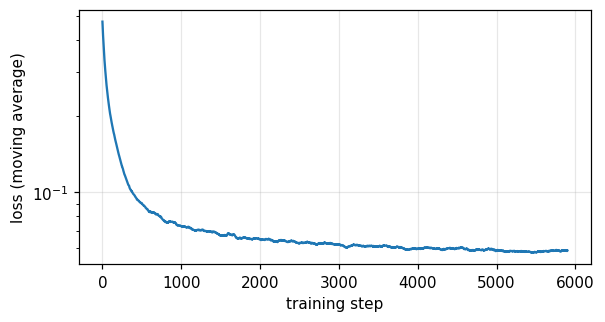

In [4]:
T, TAU_MIN, NUM_STEPS, BATCH = 5.0, 1e-3, 6000, 128
sigma = lambda tau: torch.sqrt(1 - torch.exp(-2 * tau))

def sample_tau(m):
    return torch.exp(math.log(TAU_MIN) + (math.log(T) - math.log(TAU_MIN)) * torch.rand(m, device=device))

model = UNet(base=32).to(device)
ckpt = Path("checkpoints/week4_unet.pt")
if ckpt.exists():
    model.load_state_dict(torch.load(ckpt, map_location=device)); print("loaded", ckpt)
else:
    opt = torch.optim.Adam(model.parameters(), lr=2e-3)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=2e-3, total_steps=NUM_STEPS)
    losses = []
    for step in range(NUM_STEPS):
        x0 = images[torch.randint(0, len(images), (BATCH,), device=device)]
        tau = sample_tau(BATCH); z = torch.randn_like(x0)
        xt = torch.exp(-tau)[:, None, None, None] * x0 + sigma(tau)[:, None, None, None] * z
        loss = ((model(xt, tau) - z)**2).mean()
        opt.zero_grad(); loss.backward(); opt.step(); sched.step()
        losses.append(loss.item())
    ckpt.parent.mkdir(exist_ok=True); torch.save(model.state_dict(), ckpt)
    plt.figure(figsize=(6, 3)); plt.semilogy(np.convolve(losses, np.ones(100) / 100, "valid"))
    plt.xlabel("training step"); plt.ylabel("loss (moving average)"); plt.show()
model.eval();

We sample with the exponential integrator on the two-phase grid, starting from $\mathcal N(0,I_n)$ and stopping at
$\delta=10^{-3}$. At the end we apply Tweedie's formula once, $\hat x_0=e^{\delta}(x+\sigma_\delta^2\hat s_\delta(x))$, to remove the small residual noise.

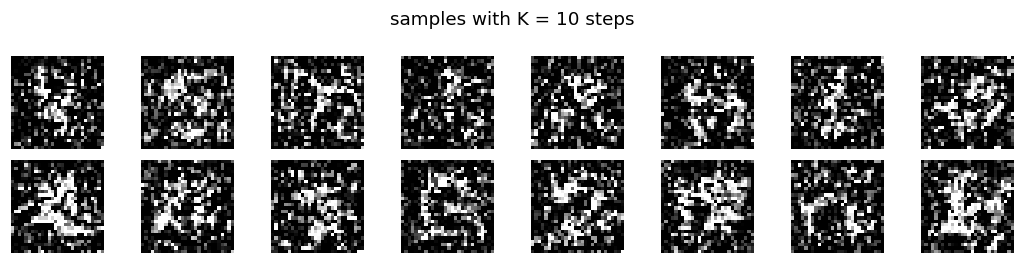

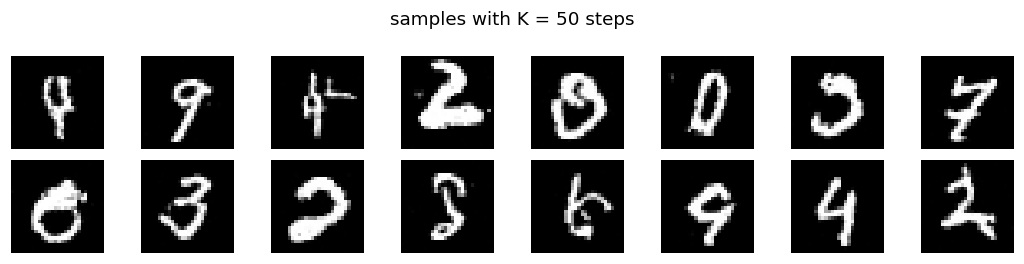

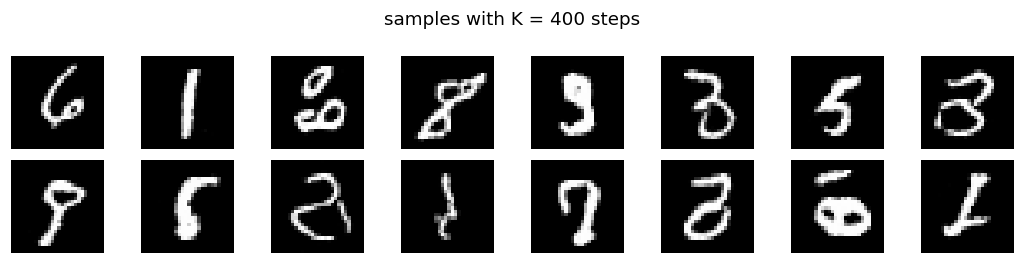

In [5]:
@torch.no_grad()
def sample(model, M, K, delta=1e-3, labels=None, guidance=None):
    ts = grid(T, delta, K, "two-phase")
    y = torch.randn(M, 1, 28, 28, device=device)
    for t0, t1 in zip(ts[:-1], ts[1:]):
        h = float(t1 - t0); tau = torch.full((M,), T - t0, device=device)
        z_hat = model(y, tau) if guidance is None else guidance(y, tau)
        score = -z_hat / sigma(tau)[:, None, None, None]
        y = math.exp(h) * y + 2 * (math.exp(h) - 1) * score + math.sqrt(math.exp(2 * h) - 1) * torch.randn_like(y)
    tau = torch.full((M,), delta, device=device)
    z_hat = model(y, tau) if guidance is None else guidance(y, tau)
    return math.exp(delta) * (y - sigma(tau)[:, None, None, None] * z_hat)       # Tweedie denoising

for K in [10, 50, 400]:
    torch.manual_seed(0)
    show(sample(model, 16, K), title=f"samples with K = {K} steps")

With too few steps the samples are blurry or broken. A few hundred steps of the two-phase grid give recognisable
digits. They are far from perfect, which is mostly due to the small network and the short training.

### Memorisation

A diffusion model trained with the *exact* score of the empirical distribution of the training set would only
reproduce training images, just as a kernel density estimator with a tiny bandwidth does (Chapter 1). Learning a score does not by itself guarantee generalisation. As a sanity check, we look for the nearest
training image of each sample.

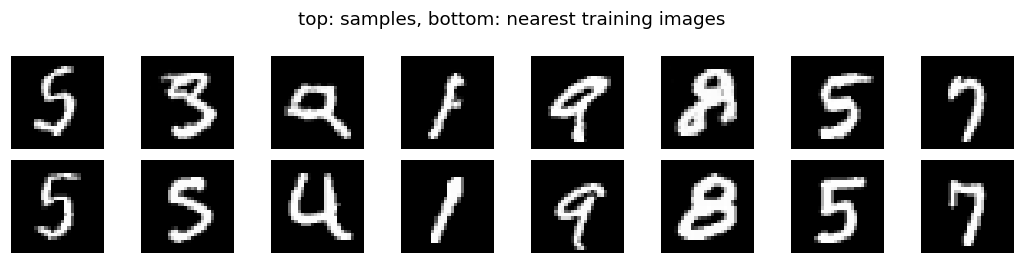

distance of each sample to its nearest training image: [ 8.2 10.3 13.4  6.8 11.1 15.3  9.   6.4]
median distance of a new test-set digit to its nearest training image: 8.8


In [6]:
torch.manual_seed(1)
gen = sample(model, 8, 400)
flat = images.view(len(images), -1)
d2 = torch.cdist(gen.view(8, -1), flat)
nearest = flat[d2.argmin(1)].view(8, 1, 28, 28)
show(torch.cat([gen, nearest]), nrow=8, title="top: samples, bottom: nearest training images")
test = torch.stack([mnist_test[i][0] for i in range(500)]).to(device).view(500, -1)
print("distance of each sample to its nearest training image:", np.round(d2.min(1).values.cpu().numpy(), 1))
print("median distance of a new test-set digit to its nearest training image:",
      round(torch.cdist(test, flat).min(1).values.median().item(), 1))

The samples are not copies of training images. They are about as far from the training set as genuinely new
handwritten digits from the test set are, which is what one expects from samples of the data distribution rather
than of the empirical distribution of the training set.

*Things to try.* Sample with the uniform grid instead of the two-phase grid and the same $K$. Replace the exponential
integrator by Euler–Maruyama. Train for only $1000$ steps and see which features of the digits appear first.